# Router Communication

In [17]:
import pandas as pd
import numpy as np

In [18]:
df1=pd.read_csv("parameters_with_kathmandu_network.csv")

In [19]:
df1

,Unnamed: 0,Initiator,Responder,End_time,Memory_size,Fidelity,Throughput,Latency (millisec),QBER
0,0,Router 1,Router 11,1.430000e+13,14,0.853306,996.427928,12.697867,0.146694
1,1,Router 1,Router 2,3.260000e+13,20,0.921327,1131.295651,15.436250,0.078673
2,2,Router 1,Router 8,2.210000e+14,12,0.971481,1130.000000,10.178914,0.028519
3,3,Router 1,Router 8,3.660000e+14,12,0.871495,1130.057179,17.488998,0.128505
4,4,Router 2,Router 7,2.580000e+13,14,0.989730,1130.000000,11.606520,0.010270
...,...,...,...,...,...,...,...,...,...
85,2,Router 1,Router 8,2.210000e+14,12,0.971481,1130.000000,10.178914,0.028519
86,3,Router 1,Router 8,3.660000e+14,12,0.871495,1130.057179,17.488998,0.128505
87,4,Router 2,Router 7,2.580000e+13,14,0.989730,1130.000000,11.606520,0.010270
88,5,Router 2,Router 12,6.640000e+13,10,0.924698,1144.520814,16.734599,0.075302


In [20]:
df1["Throughput"].mean()

1160.2813899599998

In [21]:
df1

,Unnamed: 0,Initiator,Responder,End_time,Memory_size,Fidelity,Throughput,Latency (millisec),QBER
0,0,Router 1,Router 11,1.430000e+13,14,0.853306,996.427928,12.697867,0.146694
1,1,Router 1,Router 2,3.260000e+13,20,0.921327,1131.295651,15.436250,0.078673
2,2,Router 1,Router 8,2.210000e+14,12,0.971481,1130.000000,10.178914,0.028519
3,3,Router 1,Router 8,3.660000e+14,12,0.871495,1130.057179,17.488998,0.128505
4,4,Router 2,Router 7,2.580000e+13,14,0.989730,1130.000000,11.606520,0.010270
...,...,...,...,...,...,...,...,...,...
85,2,Router 1,Router 8,2.210000e+14,12,0.971481,1130.000000,10.178914,0.028519
86,3,Router 1,Router 8,3.660000e+14,12,0.871495,1130.057179,17.488998,0.128505
87,4,Router 2,Router 7,2.580000e+13,14,0.989730,1130.000000,11.606520,0.010270
88,5,Router 2,Router 12,6.640000e+13,10,0.924698,1144.520814,16.734599,0.075302


In [22]:
df1["Fidelity"].describe()

count    90.000000
mean      0.924750
std       0.041111
min       0.851053
25%       0.888891
50%       0.926248
75%       0.950166
max       0.998604
Name: Fidelity, dtype: float64

In [23]:
df1["Throughput"].describe()

count      90.000000
mean     1160.281390
std       121.313021
min       941.689777
25%      1130.000000
50%      1132.083544
75%      1144.520814
max      1545.869630
Name: Throughput, dtype: float64

In [24]:
df1["Latency (millisec)"].describe()

count    90.000000
mean     15.161320
std       3.096637
min      10.000014
25%      12.326939
50%      15.436250
75%      18.198605
max      19.935386
Name: Latency (millisec), dtype: float64

In [25]:
df1["QBER"].describe()

count    90.000000
mean      0.075250
std       0.041111
min       0.001396
25%       0.049834
50%       0.073752
75%       0.111109
max       0.148947
Name: QBER, dtype: float64

In [26]:
corr_Fid_Th = df1['Fidelity'].corr(df1['Throughput'])
corr_Fid_Th

-0.08446890183887346

In [27]:
corr_Fid_Lat = df1['Fidelity'].corr(df1['Latency (millisec)'])
corr_Fid_Lat

-0.07819896172585293

In [28]:
corr_La_QBER = df1['Throughput'].corr(df1['QBER'])
corr_La_QBER

0.08446890183887365

In [29]:
import numpy as np
from scipy.stats import pearsonr
from math import atanh, tanh, sqrt

def correlation_with_ci(x, y, alpha=0.05):
    # Pearson correlation + p-value
    r, p = pearsonr(x, y)

    # Fisher z-transform
    z = atanh(r)
    n = len(x)
    se = 1 / sqrt(n - 3)

    # z confidence interval
    z_crit = 1.96  # for 95% CI
    z_lower = z - z_crit * se
    z_upper = z + z_crit * se

    # Convert back to r
    r_lower = tanh(z_lower)
    r_upper = tanh(z_upper)

    return r, p, r_lower, r_upper

In [30]:
pairs = [
    ('Fidelity', 'Throughput'),
    ('Fidelity', 'Latency (millisec)'),
    ('Throughput', 'QBER')
]

for a, b in pairs:
    r, p, low, high = correlation_with_ci(df1[a], df1[b])
    print(f"{a} vs {b}")
    print(f"  r = {r:.4f}")
    print(f"  p = {p:.4f}")
    print(f"  95% CI = [{low:.4f}, {high:.4f}]")
    print()


Fidelity vs Throughput
  r = -0.0845
  p = 0.4286
  95% CI = [-0.2866, 0.1248]

Fidelity vs Latency (millisec)
  r = -0.0782
  p = 0.4638
  95% CI = [-0.2807, 0.1310]

Throughput vs QBER
  r = 0.0845
  p = 0.4286
  95% CI = [-0.1248, 0.2866]



# Visulaization

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

/home/chitran/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


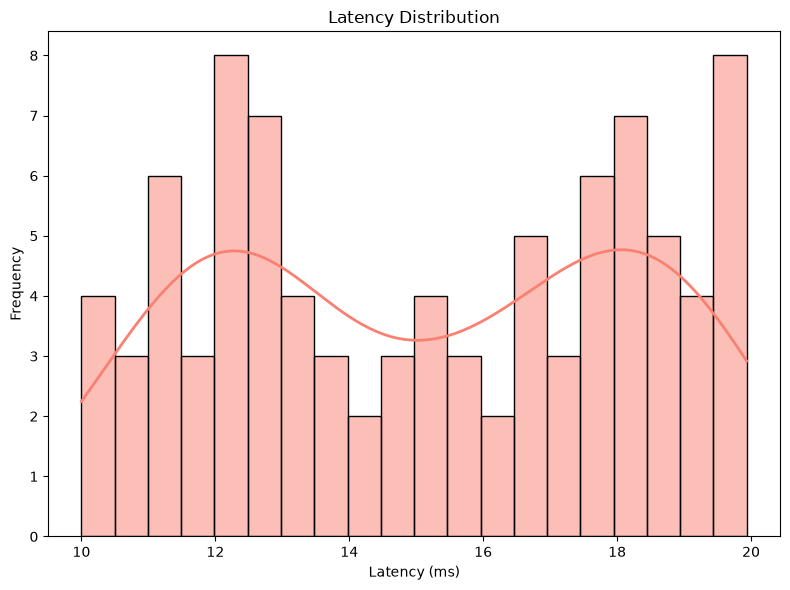

In [32]:
# LATENCY PLOT
plt.figure(figsize=(8, 6))
sns.histplot(
    df1['Latency (millisec)'], 
    kde=True, 
    color='salmon', 
    bins=20, 
    edgecolor='black', 
    line_kws={'linewidth': 2}  # Make KDE line thicker using line_kws
)
plt.title('Latency Distribution')
plt.xlabel('Latency (ms)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

/home/chitran/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


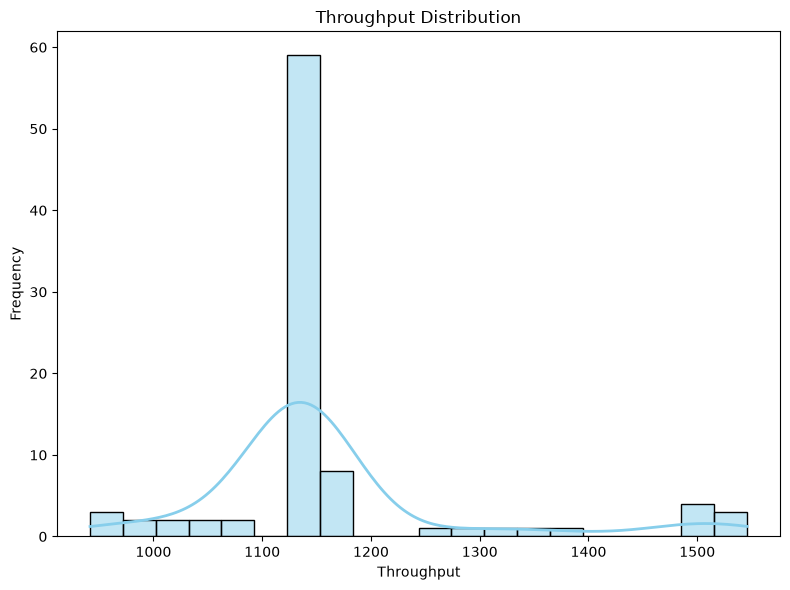

In [33]:
# THROUGH PUT PLOT
plt.figure(figsize=(8, 6))
sns.histplot(
    df1['Throughput'], 
    kde=True, 
    color='skyblue', 
    bins=20, 
    edgecolor='black', 
    line_kws={'linewidth': 2}  # Make KDE line thicker using line_kws
)
plt.title('Throughput Distribution')
plt.xlabel('Throughput')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

<Axes: xlabel='Fidelity', ylabel='Latency (millisec)'>

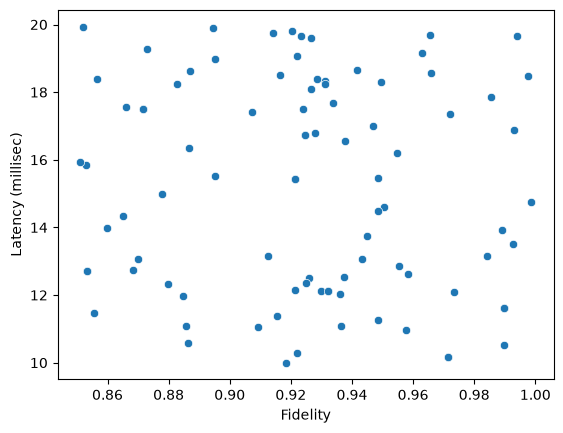

In [34]:
sns.scatterplot(x='Fidelity', y='Latency (millisec)', data=df1)

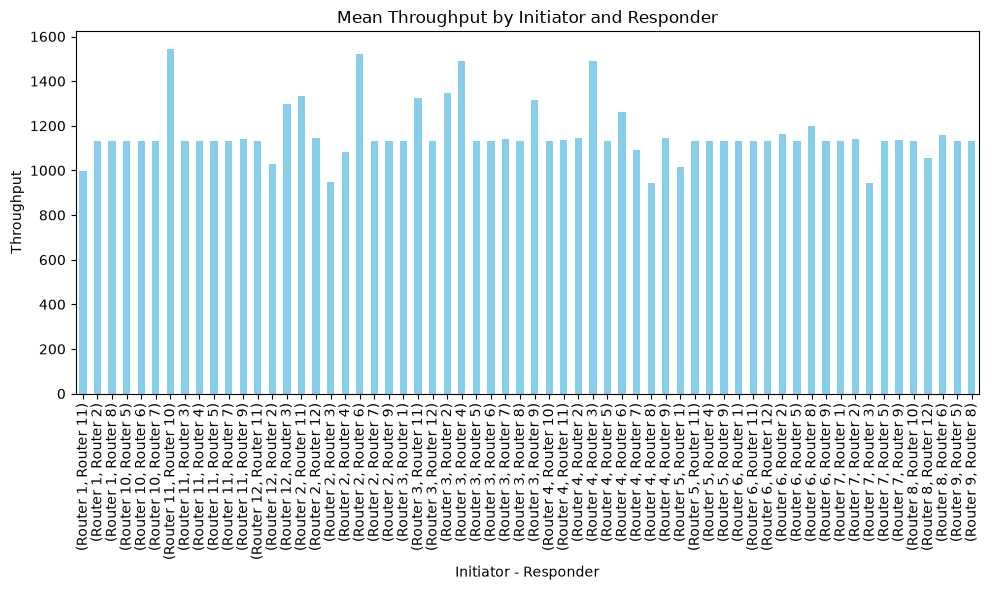

In [35]:
# Plot for Throughput with a specific color
plt.figure(figsize=(10, 6))
df1.groupby(['Initiator', 'Responder'])['Throughput'].mean().plot(kind='bar', color='skyblue')
plt.title('Mean Throughput by Initiator and Responder')
plt.xlabel('Initiator - Responder')
plt.ylabel('Throughput')
plt.tight_layout()
plt.show()

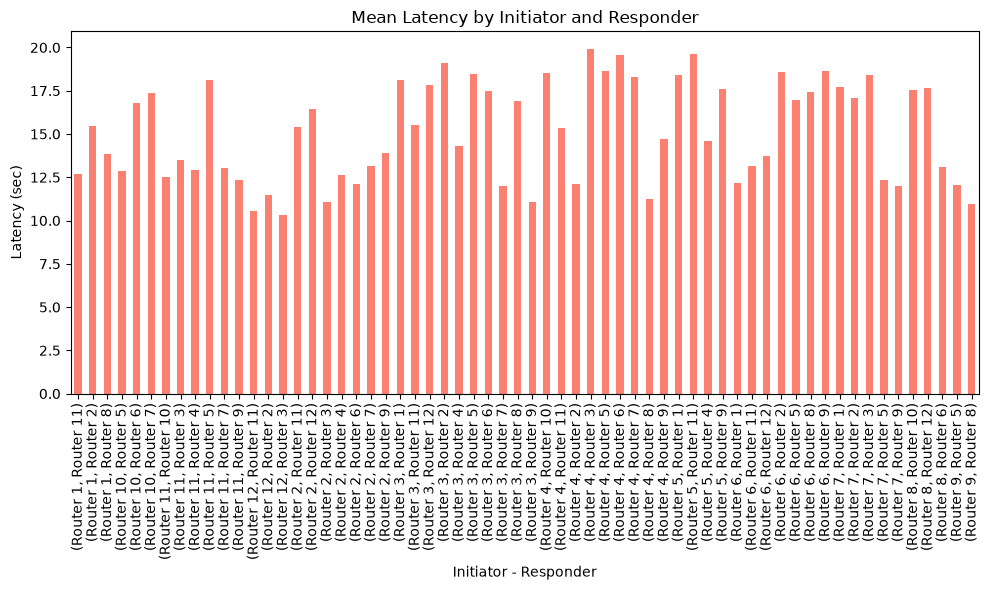

In [36]:
# Plot for Latency with a different color
plt.figure(figsize=(10, 6))
df1.groupby(['Initiator', 'Responder'])['Latency (millisec)'].mean().plot(kind='bar', color='salmon')
plt.title('Mean Latency by Initiator and Responder')
plt.xlabel('Initiator - Responder')
plt.ylabel('Latency (sec)')
plt.tight_layout()
plt.show()

/home/chitran/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


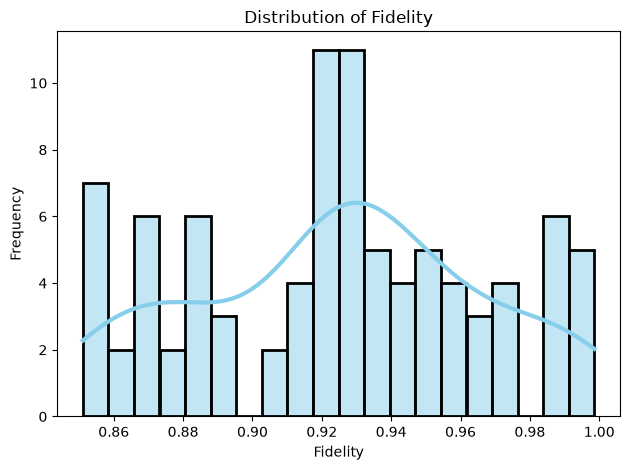

In [37]:
sns.histplot(df1['Fidelity'], kde=True, color='skyblue', bins=20, edgecolor='black', linewidth=2, line_kws={'linewidth': 3})
plt.title('Distribution of Fidelity')
plt.xlabel('Fidelity')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [38]:
df1["QBER"]=1-df1["Fidelity"]

In [39]:
df1["QBER"].describe()

count    90.000000
mean      0.075250
std       0.041111
min       0.001396
25%       0.049834
50%       0.073752
75%       0.111109
max       0.148947
Name: QBER, dtype: float64

/home/chitran/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


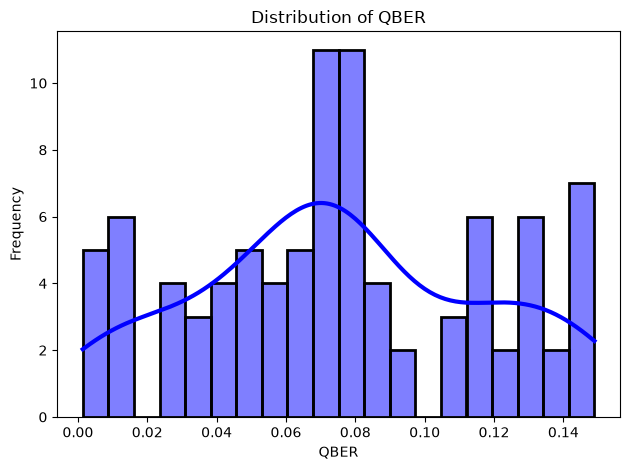

In [40]:
sns.histplot(df1['QBER'], kde=True, color='blue', bins=20, edgecolor='black', linewidth=2, line_kws={'linewidth': 3})
plt.title('Distribution of QBER')
plt.xlabel('QBER')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [41]:
df1

,Unnamed: 0,Initiator,Responder,End_time,Memory_size,Fidelity,Throughput,Latency (millisec),QBER
0,0,Router 1,Router 11,1.430000e+13,14,0.853306,996.427928,12.697867,0.146694
1,1,Router 1,Router 2,3.260000e+13,20,0.921327,1131.295651,15.436250,0.078673
2,2,Router 1,Router 8,2.210000e+14,12,0.971481,1130.000000,10.178914,0.028519
3,3,Router 1,Router 8,3.660000e+14,12,0.871495,1130.057179,17.488998,0.128505
4,4,Router 2,Router 7,2.580000e+13,14,0.989730,1130.000000,11.606520,0.010270
...,...,...,...,...,...,...,...,...,...
85,2,Router 1,Router 8,2.210000e+14,12,0.971481,1130.000000,10.178914,0.028519
86,3,Router 1,Router 8,3.660000e+14,12,0.871495,1130.057179,17.488998,0.128505
87,4,Router 2,Router 7,2.580000e+13,14,0.989730,1130.000000,11.606520,0.010270
88,5,Router 2,Router 12,6.640000e+13,10,0.924698,1144.520814,16.734599,0.075302


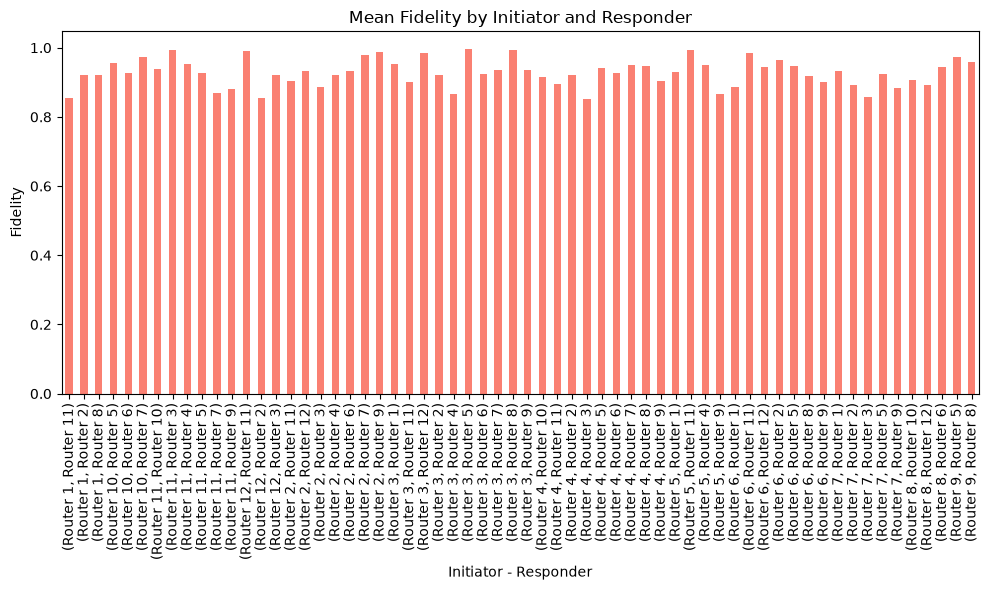

In [43]:
# Plot for Latency with a different color
plt.figure(figsize=(10, 6))
df1.groupby(['Initiator', 'Responder'])['Fidelity'].mean().plot(kind='bar', color='salmon')
plt.title('Mean Fidelity by Initiator and Responder')
plt.xlabel('Initiator - Responder')
plt.ylabel('Fidelity')
plt.tight_layout()
plt.show()